# Forensic Auditing & Algorithmic Anti-Collusion Infrastructure
## Bulgarian National Recovery and Resilience Plan (NRRP / НПВУ) Procedure BG-RRP-1.015 "School STEM Environment"

**Deterministic Random Seed:** $\text{SEED} = 42$

---

## Introduction
Public procurement accounts for about 12% of GDP in OECD countries and is the government activity most exposed to waste and corruption (OECD, 2016). The procedure BG-RRP-1.015 "School STEM Environment" of the Bulgarian National Recovery and Resilience Plan is a case in which many small buyers, the schools, purchased similar equipment under rules that allow direct awards below legal value limits. The records of the Single Information Portal ISUN 2020 for this procedure contain 2,228 projects and 11,128 contracts (ISUN 2020, 2026). This notebook asks whether the contract values and the relations between buyers and suppliers in this programme show the patterns that the literature associates with manipulation of values and restricted competition, and how much of the programme's spending is affected. The indicators it produces are diagnostic signals, not findings of illegality.

## Theoretical Background

* **Discretionary Thresholds and the Manipulation of Contract Values.** Rules that let the buyer skip open competition below a value limit create an incentive to understate the estimated value of a contract. Where such a limit was introduced, estimated values accumulated just below it, and the accumulation was strongest among winners with concealed ownership (Palguta and Pertold, 2017). The same pattern, together with a fall in the density of contracts just above the limit, appears when discretion is granted below a limit in another country (Szűcs, 2024). Both studies therefore read a break in the density of contract values at a limit as evidence of manipulation, and compare the observed density with the one expected without the limit.
* **Discretion, Competition and Favouritism.** What happens after the value is brought under the limit is a separate question. In the Czech data the tenders concerned attracted fewer bids and ended at higher prices relative to the estimated value (Palguta and Pertold, 2017). In the Hungarian data discretion raised prices, selected less productive contractors and favoured firms connected to the governing party (Szűcs, 2024). Because buyers sort themselves below the limit, a simple comparison of contracts on either side of it is biased, and the effect is identified with a structural model of the buyer's choice of procedure (Szűcs, 2024).
* **Red Flags in the Procurement Cycle.** Beyond thresholds, integrity work lists the patterns that signal risk along the whole cycle: splitting a contract to stay below a threshold, tailor-made specifications, direct awards without justification, bid-rigging in its several forms and conflicts of interest of evaluators (OECD, 2016). Several of these leave a trace that can be screened for in data, including by combining procurement files with company and tax registers (OECD, 2016). Splitting is closely related to bunching: both respond to the same limit, one by lowering the estimated value and the other by dividing it.
* **Institutional Setting in Bulgaria.** In Bulgaria the limits below which a contracting authority may award a contract directly are set in the Public Procurement Act, and they were changed with effect from 1 January 2024 (Bulgaria, 2023, Art. 20(4)). A contract is therefore compared with different limits depending on its date.
* **Research Gap and Analytical Framework.** The evidence on thresholds comes from national procurement data of two countries and from one reform in each. It says little about a single programme in which many small buyers purchase similar equipment. This study applies the threshold test and red-flag screening to such a programme. It expects contract values to accumulate just below the legal limits and treats other red flags as additional risk indicators. The framework distinguishes four levels, which are a working structure of this study and not a finding. (1) *Funding and contracting authority:* funds of the Recovery and Resilience Plan reach schools, which award the contracts. (2) *Local and regional influence:* municipalities and the regional education directorates stand in institutional relations with schools. (3) *Supplier groups:* firms supplying construction, equipment and consultancy may appear together across the same buyers. (4) *Audit record:* the records of ISUN 2020 and the audit reports of the State Financial Inspection Agency (ADFI) allow the indicators to be compared with the outcome of inspections. The available data record the winning supplier only, so competition cannot be measured directly.

*Further sources are added to this section in the steps in which the corresponding methods are used.*

---

## 1. Scientific Stack Verification & Dependency Audit

The analysis requires the package versions listed in `requirements.txt`. Each package has the following role:

- **`numpy` ($\ge 2.5.4$) & `scipy` ($\ge 1.18.1$):** Array computation, hypergeometric tests for the validation of network links, and permutation null models.
- **`pandas` ($\ge 3.1.0$):** Tabular data processing, datetime indexing, multi-key aggregations, and high-throughput filtering.
- **`networkx` ($\ge 3.7$):** Construction of bipartite buyer-supplier networks $B = (S, V, E)$, their projection onto suppliers that share buyers, $k$-core decomposition and community detection.
- **`scikit-learn` ($\ge 1.9.1$) & `statsmodels` ($\ge 0.15.0$):** Polynomial counterfactual density estimation (bunching), Quasi-Maximum Likelihood (QML) Poisson regressions, and Regression Discontinuity Design (RDD).
- **`matplotlib` ($\ge 3.11.2$) & `seaborn` ($\ge 0.13.2$):** Figures at $300\text{ DPI}$.
- **`lxml` ($\ge 6.1.3$) & `xmlschema` ($\ge 4.3.2$):** Stream parsing and XML Schema Definition (XSD) validation of the $158\text{ MB}$ ISUN open-data file (`openData.xml`).
- **`torch` ($\ge 2.11.0$, CUDA 12.8 build):** GPU acceleration of Monte Carlo and stratified permutation tests on the buyer-supplier network.

**Environment installation.** Run from the notebook directory:

```
python -m pip install -r requirements.txt --extra-index-url https://download.pytorch.org/whl/cu128
```

The extra index provides the CUDA 12.8 build of `torch` required in `requirements.txt`.

In [1]:
import os
import sys
from pathlib import Path

# Windows: make the bundled MKL DLLs importable before the scientific stack loads
DLL_DIR = Path(sys.prefix) / "Library" / "bin"
if os.name == "nt" and DLL_DIR.is_dir():
    os.add_dll_directory(str(DLL_DIR))

import importlib.metadata as importlib_metadata

from packaging.version import Version

REQUIRED_VERSIONS: dict[str, str] = {
    "numpy": "2.5.4",
    "scipy": "1.18.1",
    "pandas": "3.1.0",
    "networkx": "3.7",
    "scikit-learn": "1.9.1",
    "matplotlib": "3.11.2",
    "seaborn": "0.13.2",
    "statsmodels": "0.15.0",
    "lxml": "6.1.3",
    "xmlschema": "4.3.2",
    "torch": "2.11.0",
    "jupyter": "1.1.1",
    "nbconvert": "7.17.2",
    "nbformat": "5.11.1",
}

below_minimum = {
    pkg: importlib_metadata.version(pkg)
    for pkg, required in REQUIRED_VERSIONS.items()
    if Version(importlib_metadata.version(pkg)) < Version(required)
}
assert not below_minimum, f"Installed versions are below requirements.txt: {below_minimum}"
print(f"All {len(REQUIRED_VERSIONS)} packages meet the minimum versions in requirements.txt.")

All 14 packages meet the minimum versions in requirements.txt.


## 2. Institutional Framework & Statutory Procurement Thresholds (PPA Art. 20)

Under the Bulgarian Public Procurement Act (Закон за обществените поръчки — ЗОП / PPA), the statutory thresholds governing direct contracting without competitive tendering (*директно възлагане*) are defined by **Article 20, Paragraph 4**.

During the implementation of Procedure BG-RRP-1.015 the thresholds were amended by State Gazette (*Държавен вестник*) No. 88 of 20 October 2023, in force from 1 January 2024. Two regimes therefore apply to the contracts, and each sets separate thresholds for goods and services and for construction works:

### Regime 1: Contracts Signed on or Before 31 December 2023
$$\text{SignatureDate} \le \text{2023-12-31}$$
Thresholds as worded until 31 December 2023 (Bulgaria, 2016, Art. 20(4)).
- **Goods and Services Threshold (Net):**
  $$T_{\text{goods/services}}^{(1)} = 30\,000.00\text{ BGN}$$
  $$T_{\text{goods/services, gross}}^{(1)} = T_{\text{goods/services}}^{(1)} \times (1 + \text{VAT\_RATE}) = 30\,000.00 \times 1.20 = 36\,000.00\text{ BGN}$$
  $$T_{\text{goods/services, EUR}}^{(1)} = \frac{30\,000.00}{\text{EUR\_BGN}} = \frac{30\,000.00}{1.95583} \approx 15\,338.76\text{ EUR}$$

- **Construction Works Threshold (Net):**
  $$T_{\text{works}}^{(1)} = 50\,000.00\text{ BGN}$$
  $$T_{\text{works, gross}}^{(1)} = T_{\text{works}}^{(1)} \times (1 + \text{VAT\_RATE}) = 50\,000.00 \times 1.20 = 60\,000.00\text{ BGN}$$
  $$T_{\text{works, EUR}}^{(1)} = \frac{50\,000.00}{\text{EUR\_BGN}} = \frac{50\,000.00}{1.95583} \approx 25\,564.59\text{ EUR}$$

---

### Regime 2: Contracts Signed on or After 1 January 2024 (SG No. 88/2023)
$$\text{SignatureDate} \ge \text{2024-01-01}$$
Thresholds as amended with effect from 1 January 2024 (Bulgaria, 2023, Art. 20(4)).
- **Goods and Services Threshold (Net):**
  $$T_{\text{goods/services}}^{(2)} = 50\,000.00\text{ BGN}$$
  $$T_{\text{goods/services, gross}}^{(2)} = T_{\text{goods/services}}^{(2)} \times (1 + \text{VAT\_RATE}) = 50\,000.00 \times 1.20 = 60\,000.00\text{ BGN}$$
  $$T_{\text{goods/services, EUR}}^{(2)} = \frac{50\,000.00}{\text{EUR\_BGN}} = \frac{50\,000.00}{1.95583} \approx 25\,564.59\text{ EUR}$$

- **Construction Works Threshold (Net):**
  $$T_{\text{works}}^{(2)} = 80\,000.00\text{ BGN}$$
  $$T_{\text{works, gross}}^{(2)} = T_{\text{works}}^{(2)} \times (1 + \text{VAT\_RATE}) = 80\,000.00 \times 1.20 = 96\,000.00\text{ BGN}$$
  $$T_{\text{works, EUR}}^{(2)} = \frac{80\,000.00}{\text{EUR\_BGN}} = \frac{80\,000.00}{1.95583} \approx 40\,903.35\text{ EUR}$$

---

### Tax Rate and Exchange Rate
$$\text{VAT\_RATE} = 0.20 \quad (20\%), \qquad \text{EUR\_BGN} = 1.95583 \quad (\text{fixed BGN/EUR rate})$$

### Theoretical Discretion & Bunching Mechanisms
Where a statutory threshold marks the transition from open competition to discretionary selection, buyers have an incentive to manipulate contract values so that they fall just below it, and contracts in the discretionary zone attract fewer competing bidders and end at higher prices (Palguta and Pertold, 2017; Szűcs, 2024).


In [2]:
from __future__ import annotations

from dataclasses import dataclass
from datetime import date, datetime
from enum import Enum
from pathlib import Path
from typing import Final, Literal


@dataclass(frozen=True)
class PathConfig:
    """Relative paths of the input files and output directories."""
    # Read-only raw data copies (data/raw/, excluded from Git)
    RAW_ISUN_XML: Final[Path] = Path("data/raw/openData.xml")
    RAW_ISUN_XSD: Final[Path] = Path("data/raw/openData.xsd")
    RAW_SCHOOLS_CSV: Final[Path] = Path("data/raw/Училища_29.03.2023_обогатена.csv")
    RAW_ADFI_DIR: Final[Path] = Path("data/raw/adfi")
    LITERATURE_SOURCES_INDEX: Final[Path] = Path("data/raw/literature/SOURCES_INDEX.md")
    LITERATURE_OUTPUTS_DIR: Final[Path] = Path("data/raw/literature/outputs")

    # Working and output directories (data/cache is excluded from Git)
    DATA_DIR: Final[Path] = Path("data")
    DERIVED_DIR: Final[Path] = Path("data/derived")
    CACHE_DIR: Final[Path] = Path("data/cache")
    FIGURES_DIR: Final[Path] = Path("reports/figures")
    TABLES_DIR: Final[Path] = Path("reports/tables")


class SubjectType(str, Enum):
    """Subject matter classification of public procurement contracts."""
    GOODS = "goods"
    SERVICES = "services"
    WORKS = "works"


@dataclass(frozen=True)
class ThresholdConfig:
    """Statutory procurement thresholds under Article 20, Paragraph 4 of the Bulgarian PPA."""
    # Macroeconomic & Statutory Constants
    VAT_RATE: Final[float] = 0.20
    EUR_BGN: Final[float] = 1.95583  # Fixed statutory currency board parity

    # Regime 1: Contracts signed on or before 2023-12-31 (Statutory net values, excluding VAT)
    REGIME_1_CUTOFF: Final[str] = "2023-12-31"
    T1_GOODS_SERVICES_NET_BGN: Final[float] = 30000.00
    T1_WORKS_NET_BGN: Final[float] = 50000.00

    # Regime 2: Contracts signed on or after 2024-01-01 (SG No. 88/2023, net values, excluding VAT)
    REGIME_2_START: Final[str] = "2024-01-01"
    T2_GOODS_SERVICES_NET_BGN: Final[float] = 50000.00
    T2_WORKS_NET_BGN: Final[float] = 80000.00

    @classmethod
    def get_regime(cls, signature_date: str | date | datetime) -> Literal[1, 2]:
        """Determine the applicable statutory PPA Art. 20 regime based on signature date."""
        if isinstance(signature_date, str):
            dt = datetime.strptime(signature_date[:10], "%Y-%m-%d").date()
        elif isinstance(signature_date, datetime):
            dt = signature_date.date()
        else:
            dt = signature_date
        
        cutoff = datetime.strptime(cls.REGIME_1_CUTOFF, "%Y-%m-%d").date()
        return 1 if dt <= cutoff else 2

    @classmethod
    def get_threshold_bgn_net(cls, signature_date: str | date | datetime, subject: SubjectType | str) -> float:
        """Return the statutory direct-award threshold in BGN excluding VAT."""
        regime = cls.get_regime(signature_date)
        subj = SubjectType(subject) if isinstance(subject, str) else subject
        
        if regime == 1:
            return cls.T1_WORKS_NET_BGN if subj == SubjectType.WORKS else cls.T1_GOODS_SERVICES_NET_BGN
        else:
            return cls.T2_WORKS_NET_BGN if subj == SubjectType.WORKS else cls.T2_GOODS_SERVICES_NET_BGN

    @classmethod
    def get_threshold_bgn_gross(cls, signature_date: str | date | datetime, subject: SubjectType | str) -> float:
        """Return the statutory direct-award threshold in BGN including 20% VAT."""
        return cls.get_threshold_bgn_net(signature_date, subject) * (1.0 + cls.VAT_RATE)

    @classmethod
    def get_threshold_eur_net(cls, signature_date: str | date | datetime, subject: SubjectType | str) -> float:
        """Return the statutory direct-award threshold in EUR excluding VAT."""
        return cls.get_threshold_bgn_net(signature_date, subject) / cls.EUR_BGN

    @classmethod
    def get_threshold_eur_gross(cls, signature_date: str | date | datetime, subject: SubjectType | str) -> float:
        """Return the statutory direct-award threshold in EUR including VAT."""
        return cls.get_threshold_bgn_gross(signature_date, subject) / cls.EUR_BGN


@dataclass(frozen=True)
class ModelConfig:
    """Global parameters for statistical inference, network filtering, and null distributions."""
    SEED: Final[int] = 42
    ALPHA_FDR: Final[float] = 0.01  # FDR significance cutoff (1%)
    MONTE_CARLO_PERMUTATIONS: Final[int] = 10000
    N_STRATIFIED_PERMUTATIONS: Final[int] = 1000
    NULL_PERCENTILES: Final[tuple[int, int]] = (80, 90)


print("Configuration dataclasses successfully initialized.")
print(f"PPA Regime 1 Cutoff: {ThresholdConfig.REGIME_1_CUTOFF} | Goods/Services Net: {ThresholdConfig.T1_GOODS_SERVICES_NET_BGN:,.2f} BGN")
print(f"PPA Regime 2 Start:  {ThresholdConfig.REGIME_2_START}  | Goods/Services Net: {ThresholdConfig.T2_GOODS_SERVICES_NET_BGN:,.2f} BGN")
print(f"VAT Rate:            {ThresholdConfig.VAT_RATE * 100:.0f}% | EUR/BGN Fixed Peg: {ThresholdConfig.EUR_BGN}")
print(f"Model SEED:          {ModelConfig.SEED} | Permutations: {ModelConfig.N_STRATIFIED_PERMUTATIONS} | FDR Alpha: {ModelConfig.ALPHA_FDR}")


Configuration dataclasses successfully initialized.
PPA Regime 1 Cutoff: 2023-12-31 | Goods/Services Net: 30,000.00 BGN
PPA Regime 2 Start:  2024-01-01  | Goods/Services Net: 50,000.00 BGN
VAT Rate:            20% | EUR/BGN Fixed Peg: 1.95583
Model SEED:          42 | Permutations: 1000 | FDR Alpha: 0.01


## 3. Thresholds and the Bunching Method: Illustrative Figures

The figures in this section introduce the legal setting and the statistical idea on which the later analysis relies. Each figure answers one question and is explained before it is drawn.

In [3]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np
import seaborn as sns

# Global publication-grade typography and aesthetic configuration
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({
    "figure.dpi": 300,
    "savefig.dpi": 300,
    "font.family": "serif",
    "font.serif": ["Times New Roman", "DejaVu Serif", "Georgia"],
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "axes.labelweight": "bold",
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "figure.titlesize": 14,
    "figure.titleweight": "bold",
})

### 3.1 Statutory Direct-Award Thresholds

**Question.** Up to which contract value may a school award a contract directly, without an open procedure, and how did that limit change during the programme?

**Why a grouped bar chart.** The law sets four discrete values: two procurement subjects (goods and services; construction works) under two regimes (contracts signed up to 31.12.2023, and from 01.01.2024). Bars on a common monetary scale make the four limits and the change between the regimes comparable at a glance.

**What each bar is.** The blue bar is the statutory value, expressed in BGN without VAT: 30,000 and 50,000 before 2024 (Bulgaria, 2016, Art. 20(4)), and 50,000 and 80,000 from 2024 (Bulgaria, 2023, Art. 20(4)). The orange bar is the same limit including 20% VAT (×1.2), and the green bar is the same limit in euro at the fixed parity of 1.95583. The orange and green bars are not separate legal limits. They are shown because contract amounts in the data are not recorded in one unit: depending on the project they are in BGN or EUR, with or without VAT. Before a contract is compared with a threshold, its amount has to be brought to the unit in which the threshold is defined, and the figure shows the same threshold in each unit.

**How to read.** Compare the blue bars across the categories for the legal limits. Read the orange and green bars only as conversions of the blue bar next to them.

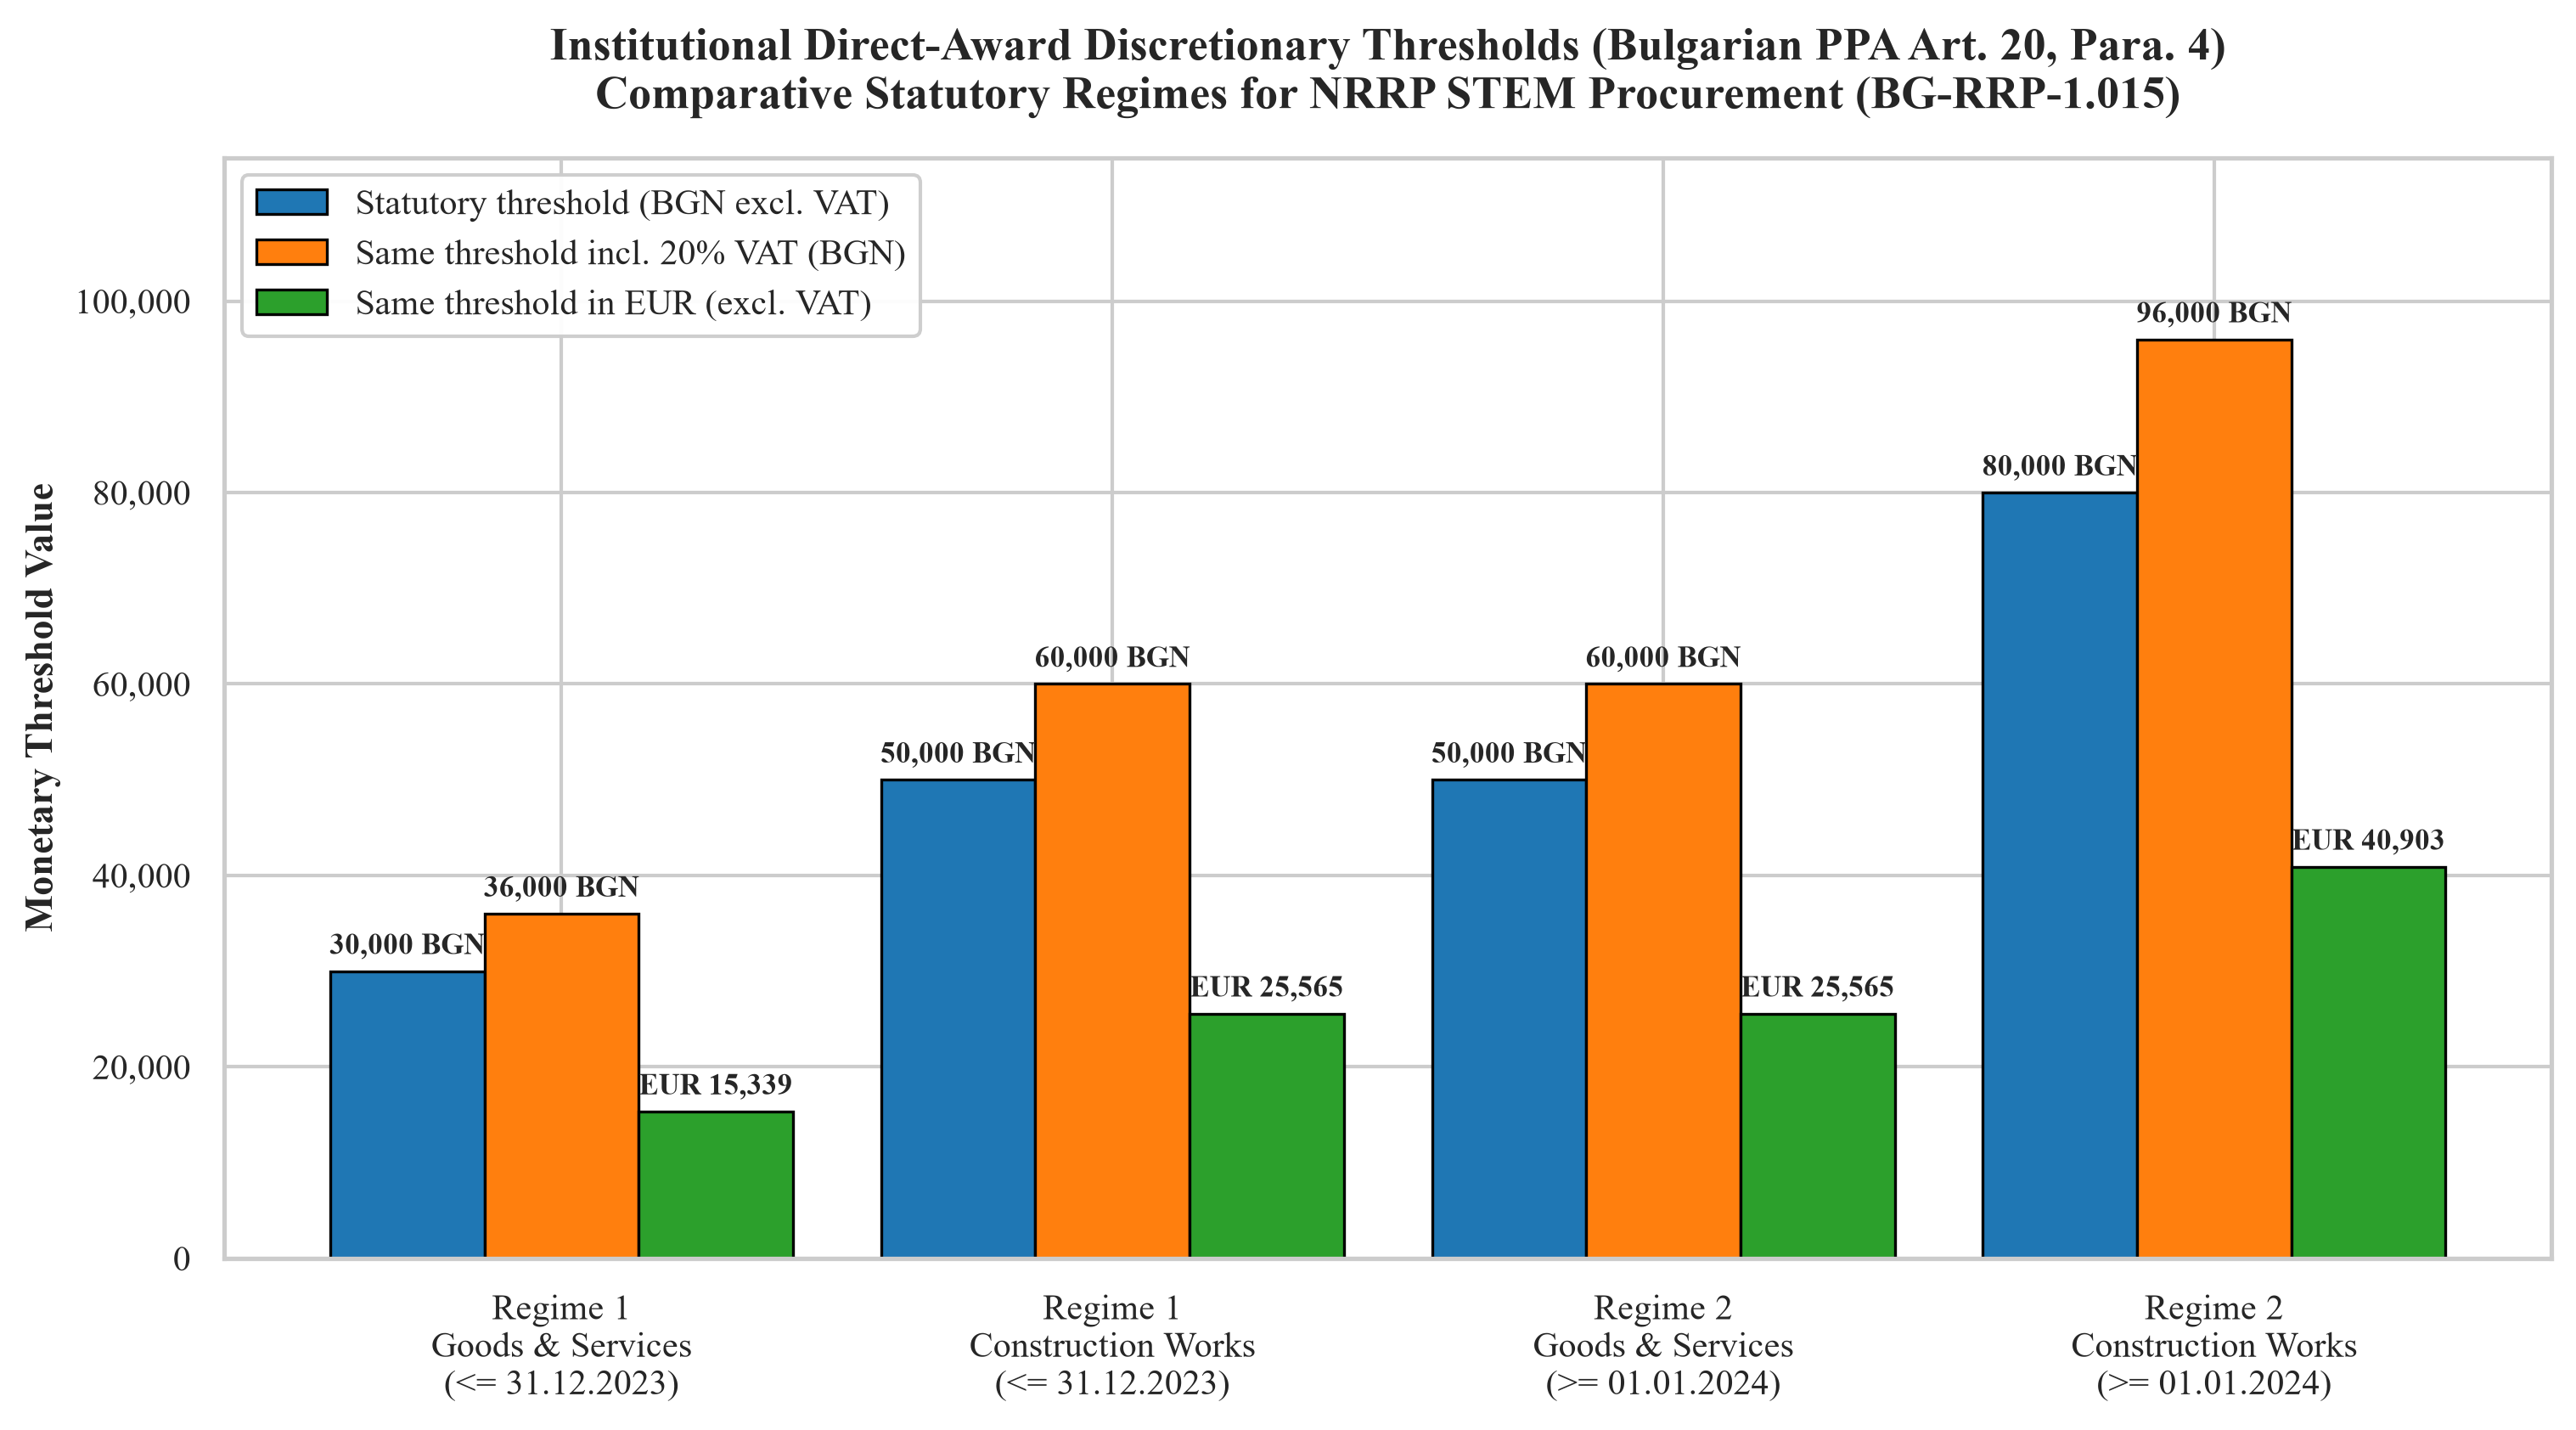

In [4]:
fig1, ax1 = plt.subplots(figsize=(10, 5.5), constrained_layout=True)

categories = [
    "Regime 1\nGoods & Services\n(<= 31.12.2023)",
    "Regime 1\nConstruction Works\n(<= 31.12.2023)",
    "Regime 2\nGoods & Services\n(>= 01.01.2024)",
    "Regime 2\nConstruction Works\n(>= 01.01.2024)",
]

net_bgn = [
    ThresholdConfig.T1_GOODS_SERVICES_NET_BGN,
    ThresholdConfig.T1_WORKS_NET_BGN,
    ThresholdConfig.T2_GOODS_SERVICES_NET_BGN,
    ThresholdConfig.T2_WORKS_NET_BGN,
]
gross_bgn = [v * (1 + ThresholdConfig.VAT_RATE) for v in net_bgn]
net_eur = [v / ThresholdConfig.EUR_BGN for v in net_bgn]

x = np.arange(len(categories))
width = 0.28

rects1 = ax1.bar(x - width, net_bgn, width, label="Statutory threshold (BGN excl. VAT)", color="#1f77b4", edgecolor="black", linewidth=0.8)
rects2 = ax1.bar(x, gross_bgn, width, label="Same threshold incl. 20% VAT (BGN)", color="#ff7f0e", edgecolor="black", linewidth=0.8)
rects3 = ax1.bar(x + width, net_eur, width, label="Same threshold in EUR (excl. VAT)", color="#2ca02c", edgecolor="black", linewidth=0.8)

ax1.set_ylabel("Monetary Threshold Value", fontweight="bold")
ax1.set_title("Institutional Direct-Award Discretionary Thresholds (Bulgarian PPA Art. 20, Para. 4)\nComparative Statutory Regimes for NRRP STEM Procurement (BG-RRP-1.015)", pad=14)
ax1.set_xticks(x)
ax1.set_xticklabels(categories, fontweight="normal")
ax1.legend(loc="upper left", frameon=True, facecolor="white", edgecolor="#cccccc", framealpha=0.95)
ax1.yaxis.set_major_formatter(ticker.FuncFormatter(lambda y, _: f"{int(y):,}"))
ax1.set_ylim(0, 115000)

def autolabel(rects, is_eur=False):
    for rect in rects:
        h = rect.get_height()
        label = f"EUR {h:,.0f}" if is_eur else f"{h:,.0f} BGN"
        ax1.annotate(label,
                    xy=(rect.get_x() + rect.get_width() / 2, h),
                    xytext=(0, 3),
                    textcoords="offset points",
                    ha="center", va="bottom", fontsize=8.5, rotation=0, fontweight="bold")

autolabel(rects1)
autolabel(rects2)
autolabel(rects3, is_eur=True)

plt.show()

**Figure 3.1.** Statutory direct-award thresholds for goods and services and for construction works under the two regimes, in net BGN, with their conversions to gross BGN and net EUR.

*Source:* Bulgaria (2016, Art. 20(4)) for contracts signed up to 31 December 2023; Bulgaria (2023, Art. 20(4)) for contracts signed from 1 January 2024.

### 3.2 Excess Mass Below a Discretionary Threshold

**Question.** If a contracting authority may award directly below a threshold, do contract values accumulate just under that threshold?

**Why a density with a counterfactual.** Contract values are expected to follow a smooth distribution. A threshold is a place where the legal consequences change abruptly, so a manipulation of values appears as a break in an otherwise smooth density. Contract values are compared with the density estimated for the case without the threshold (the counterfactual), and the difference just below the threshold is the excess mass, $B = \sum_j (c_j - \hat{c}_j)$, together with the missing mass above it (Palguta and Pertold, 2017).

**How to read.** The dashed blue line is the counterfactual density $\hat{c}(z)$. The solid red line is the observed density $c(z)$ with the bunching pattern. The hatched area is the excess mass $B$. The dotted vertical line is the threshold $T = 50\,000$ BGN net, which applies to construction works before 2024 and to goods and services from 2024.

**What the figure is not.** It is a stylised illustration of the method with illustrative values, not an estimate from the contract data. A concentration below a threshold is a warning sign that calls for an explanation, not proof of a violation.

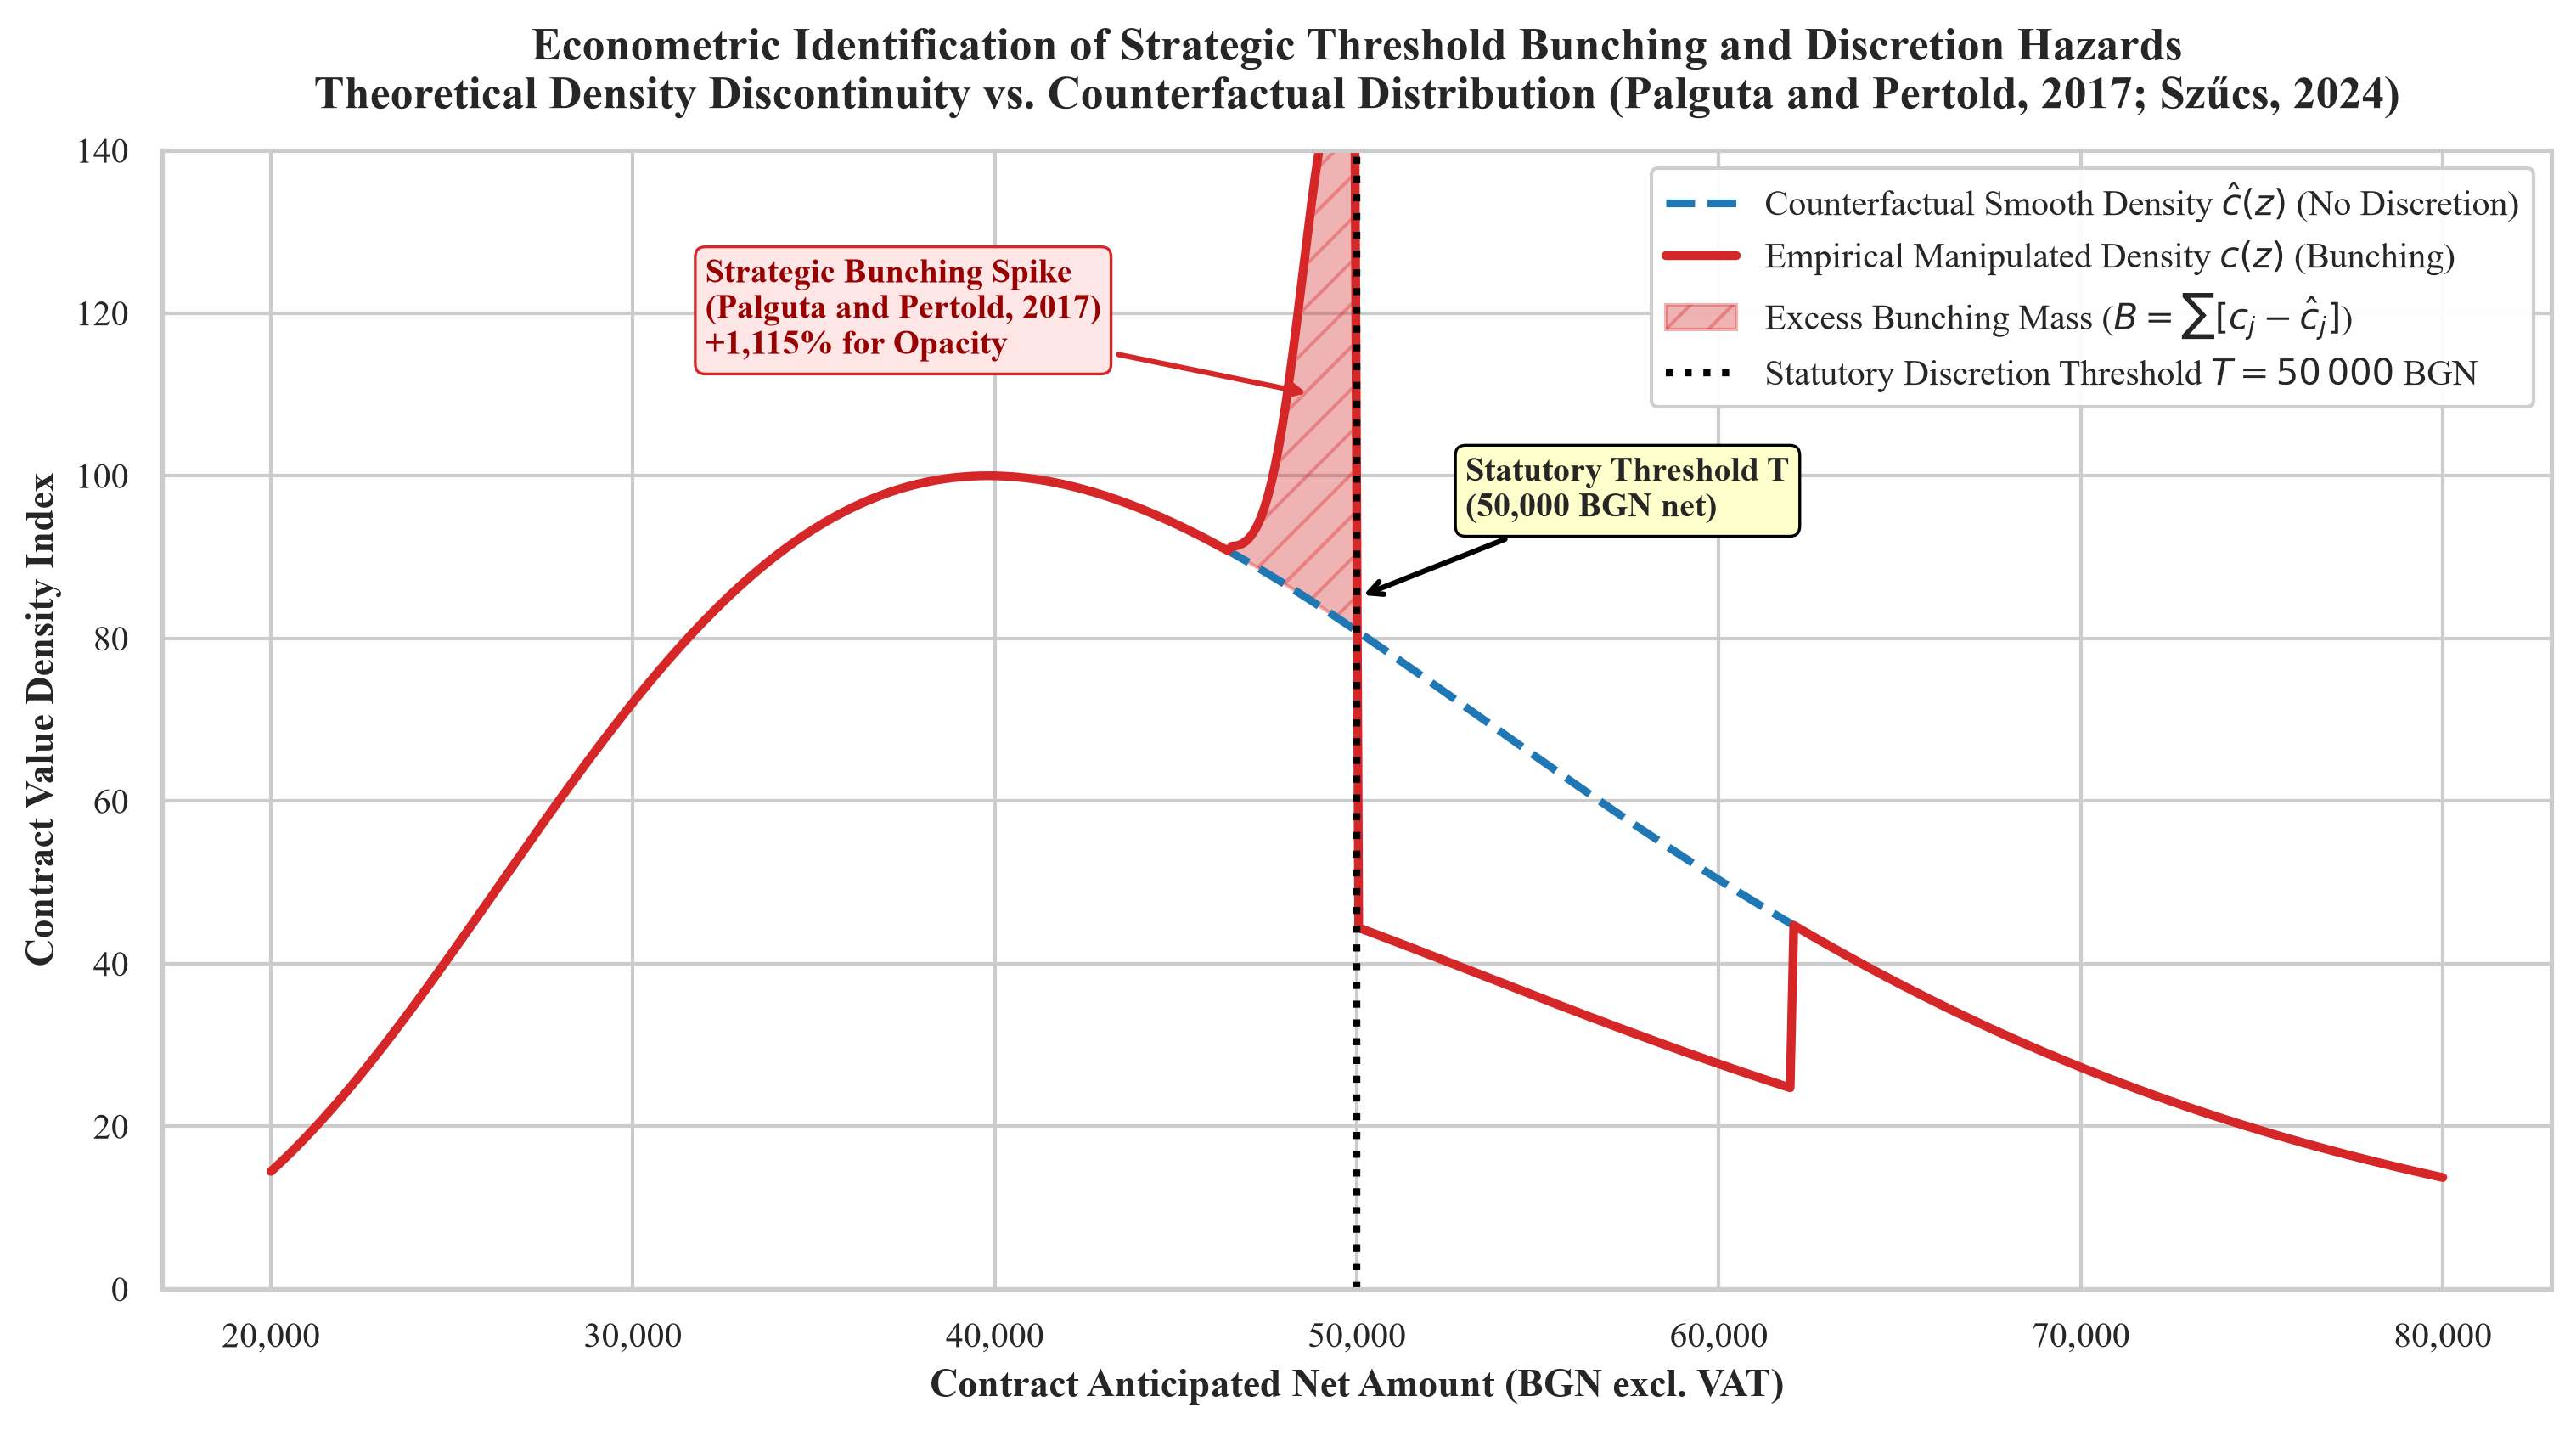

In [5]:
threshold_val = 50000.0  # Regime 1 Works / Regime 2 Goods threshold
v_axis = np.linspace(20000, 80000, 600)

# Counterfactual smooth log-normal distribution (unmanipulated market density)
mu, sigma = np.log(45000), 0.35
cf_density = (1 / (v_axis * sigma * np.sqrt(2 * np.pi))) * np.exp(-((np.log(v_axis) - mu)**2) / (2 * sigma**2))
cf_density = cf_density / np.max(cf_density) * 100.0  # Normalized index

# Empirical manipulated density with strategic bunching spike just below threshold (Palguta and Pertold, 2017)
manipulated_density = cf_density.copy()
above_mask = (v_axis >= threshold_val) & (v_axis <= threshold_val + 12000)
manipulated_density[above_mask] *= 0.55
bunch_mask = (v_axis >= threshold_val - 3500) & (v_axis < threshold_val)
manipulated_density[bunch_mask] += 65.0 * np.exp(-((v_axis[bunch_mask] - (threshold_val - 500))**2) / (2 * (1000**2)))

fig2, ax2 = plt.subplots(figsize=(10, 5.5), constrained_layout=True)

ax2.plot(v_axis, cf_density, color="#1f77b4", linestyle="--", linewidth=2.2, label=r"Counterfactual Smooth Density $\hat{c}(z)$ (No Discretion)")
ax2.plot(v_axis, manipulated_density, color="#d62728", linestyle="-", linewidth=2.5, label=r"Empirical Manipulated Density $c(z)$ (Bunching)")

ax2.fill_between(v_axis[bunch_mask], cf_density[bunch_mask], manipulated_density[bunch_mask],
                 color="#d62728", alpha=0.35, hatch="//", label=r"Excess Bunching Mass ($B = \sum [c_j - \hat{c}_j]$)")

ax2.axvline(threshold_val, color="black", linestyle=":", linewidth=2.0, label=r"Statutory Discretion Threshold $T = 50\,000$ BGN")
ax2.annotate(f"Statutory Threshold T\n({threshold_val:,.0f} BGN net)",
             xy=(threshold_val, 85), xytext=(threshold_val + 3000, 95),
             arrowprops=dict(arrowstyle="->", color="black", lw=1.5),
             fontsize=9.5, fontweight="bold", bbox=dict(boxstyle="round,pad=0.3", fc="#ffffcc", ec="black", lw=0.8))

ax2.annotate("Strategic Bunching Spike\n(Palguta and Pertold, 2017)\n+1,115% for Opacity",
             xy=(threshold_val - 1200, 110), xytext=(threshold_val - 18000, 115),
             arrowprops=dict(arrowstyle="->", color="#d62728", lw=1.5),
             fontsize=9.5, fontweight="bold", color="#990000",
             bbox=dict(boxstyle="round,pad=0.3", fc="#ffe6e6", ec="#d62728", lw=0.8))

ax2.set_xlabel("Contract Anticipated Net Amount (BGN excl. VAT)", fontweight="bold")
ax2.set_ylabel("Contract Value Density Index", fontweight="bold")
ax2.set_title("Econometric Identification of Strategic Threshold Bunching and Discretion Hazards\nTheoretical Density Discontinuity vs. Counterfactual Distribution (Palguta and Pertold, 2017; Szűcs, 2024)", pad=12)
ax2.legend(loc="upper right", frameon=True, facecolor="white", framealpha=0.95)
ax2.set_ylim(0, 140)
ax2.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, _: f"{int(x):,}"))

plt.show()

**Figure 3.2.** Stylised density of contract values around a discretionary threshold, with the counterfactual density and the excess mass below the threshold (illustrative values).

*Source:* author's illustration based on Palguta and Pertold (2017).

### 3.3 Competition Around the Threshold

**Question.** Does discretion in the award go together with less competition?

**Why a line comparison of bidder numbers.** Discretionary awards go together with fewer competing bidders (Szűcs, 2024). If the contracting authority chooses whom to invite, the average number of bidders below the threshold should be lower than an open procedure would attract at the same contract value. A line plotted against the contract value shows whether such a gap exists and whether it appears exactly at the threshold, which is what separates the effect of the rule from the effect of contract size.

**How to read.** The dashed blue line is the number of bidders expected under an open procedure. The solid green line is the number under discretion, which drops at the threshold. The dotted vertical line is the threshold, as in the previous figure. An average close to one bidder below the threshold means that a single bidder is the typical outcome there.

**What the figure is not.** It is the same kind of stylised illustration with illustrative values and does not use the contract data. The ISUN records name only the winning supplier, so the number of bidders cannot be observed in this study. The figure shows the mechanism that the threshold test of Figure 3.2 detects indirectly.

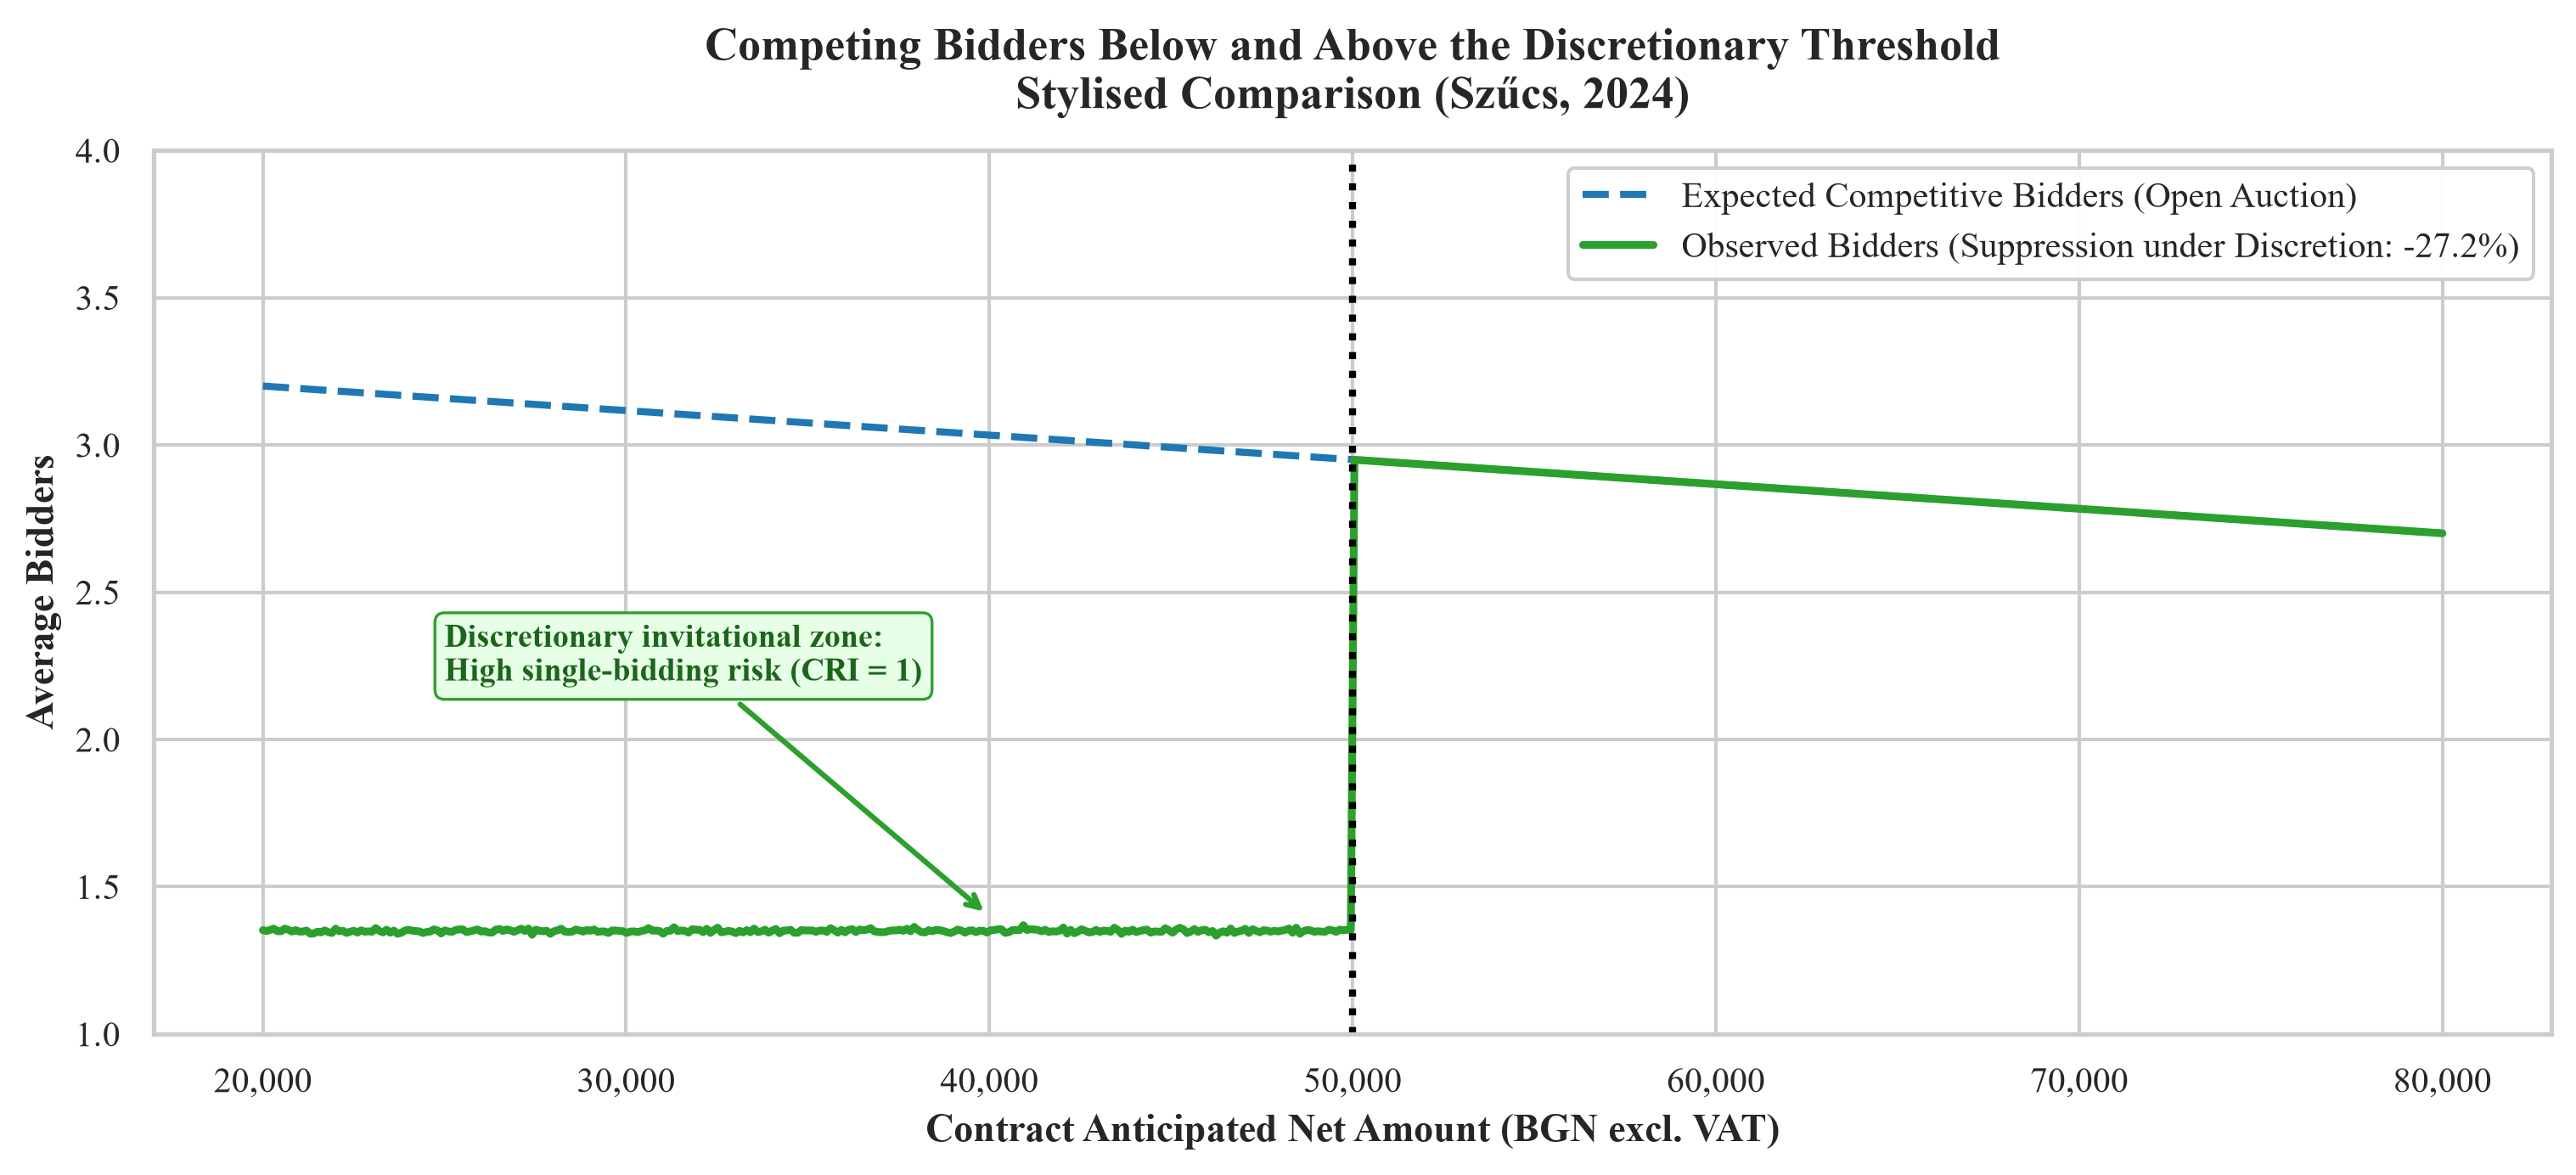

In [6]:
np.random.seed(ModelConfig.SEED)

# Number of competitive bidders (Szűcs, 2024; Palguta and Pertold, 2017)
bidders_cf = 3.2 - 0.5 * ((v_axis - 20000) / 60000)
bidders_obs = np.where(v_axis < threshold_val, 1.35 + 0.1 * np.random.normal(0, 0.05, len(v_axis)), bidders_cf)

fig3, ax3 = plt.subplots(figsize=(10, 4.5), constrained_layout=True)

ax3.plot(v_axis, bidders_cf, color="#1f77b4", linestyle="--", linewidth=2.0, label="Expected Competitive Bidders (Open Auction)")
ax3.plot(v_axis, bidders_obs, color="#2ca02c", linestyle="-", linewidth=2.2, label="Observed Bidders (Suppression under Discretion: -27.2%)")
ax3.axvline(threshold_val, color="black", linestyle=":", linewidth=2.0)

ax3.annotate("Discretionary invitational zone:\nHigh single-bidding risk (CRI = 1)",
             xy=(threshold_val - 10000, 1.4), xytext=(threshold_val - 25000, 2.2),
             arrowprops=dict(arrowstyle="->", color="#2ca02c", lw=1.5),
             fontsize=9.0, fontweight="bold", color="#1b661b",
             bbox=dict(boxstyle="round,pad=0.3", fc="#e6ffe6", ec="#2ca02c", lw=0.8))

ax3.set_xlabel("Contract Anticipated Net Amount (BGN excl. VAT)", fontweight="bold")
ax3.set_ylabel("Average Bidders", fontweight="bold")
ax3.set_title("Competing Bidders Below and Above the Discretionary Threshold\nStylised Comparison (Szűcs, 2024)", pad=12)
ax3.set_ylim(1.0, 4.0)
ax3.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, _: f"{int(x):,}"))
ax3.legend(loc="upper right", frameon=True, facecolor="white", framealpha=0.95)

plt.show()

**Figure 3.3.** Stylised average number of competing bidders below and above a discretionary threshold (illustrative values).

*Source:* author's illustration based on Szűcs (2024).

## 4. Neutrality Statement & Epistemic Disclaimer

The following principles apply to all results of this notebook:
1. **Risk Indicators vs. Judicial Findings:** Statistical anomalies, bunching below thresholds and clusters in the buyer-supplier network identified in this notebook are **diagnostic risk indicators**. They do not constitute formal judicial determinations of illegality, cartel operation, or statutory violations.
2. **Confidentiality & Privacy:** In accordance with the General Data Protection Regulation (European Union, 2016), all personal identifying details (such as Unified Civil Numbers / EGN, personal physical addresses, and personal contact numbers) are strictly excluded from all code, configurations, logs, and derived datasets. Public officials are referenced exclusively by their institutional role and institutional identifiers.


## References

**Bulgaria (2016)**. *Public Procurement Act* (Закон за обществените поръчки). State Gazette, No. 13, 16 February 2016, Art. 20(4) in the wording in force until 31 December 2023.

**Bulgaria (2023)**. *Public Procurement Act* (Закон за обществените поръчки). State Gazette, No. 13, 16 February 2016, Art. 20(4) as amended by State Gazette, No. 88, 20 October 2023, in force from 1 January 2024.

**European Union (2016)**. *Regulation (EU) 2016/679 of the European Parliament and of the Council of 27 April 2016 on the protection of natural persons with regard to the processing of personal data and on the free movement of such data (General Data Protection Regulation)*. Official Journal of the European Union, L 119, 4 May 2016, pp. 1–88.

**ISUN 2020 (2026)**. *Single Information Web Portal for General Information on the Management of EU Structural and Cohesion Funds in the Republic of Bulgaria: Open Data Module*. Sofia: Ministry of Finance. [online] Available at: https://2020.eufunds.bg/bg/0/0/OpenData [Accessed: 1 November 2026].

**OECD (2016)**. *Preventing Corruption in Public Procurement*. Paris: OECD Publishing. [online] Available at: https://www.oecd.org/content/dam/oecd/en/topics/policy-sub-issues/integrity-in-public-procurement/corruption-public-procurement-brochure.pdf [Accessed: 1 November 2026].

**Palguta, J. and Pertold, F. (2017)**. 'Manipulation of procurement contracts: Evidence from the introduction of discretionary thresholds', *American Economic Journal: Economic Policy*, 9(2), pp. 293–319. [online] Available at: https://www.cerge-ei.cz/pdf/wp/Wp501.pdf [Accessed: 1 November 2026]. doi: [10.1257/pol.20150511](https://doi.org/10.1257/pol.20150511).

**Szűcs, F. (2024)**. 'Discretion and favoritism in public procurement', *Journal of the European Economic Association*, 22(1), pp. 117–160. doi: [10.1093/jeea/jvad017](https://doi.org/10.1093/jeea/jvad017).